# Predicting 30-Day Hospital Readmissions for Diabetic Patients

**Author:** Jobayer Ibne Saidur · Business Analytics, University of the Cumberlands

**Business question:** Which diabetic patients are most likely to come back to the hospital within 30 days of discharge, and is it worth paying for a follow-up program that targets them?

**Why it matters:** An unplanned readmission costs U.S. hospitals about **$16,300** on average (AHRQ HCUP, 2020), and Medicare's Hospital Readmissions Reduction Program penalizes hospitals with high readmission rates. Post-discharge programs such as care-transition coaching cost a few hundred dollars per patient, so the question is *who* to enroll.

**Data:** 101,766 inpatient stays of diabetic patients at 130 U.S. hospitals, 1999 to 2008 (UCI Machine Learning Repository; Strack et al., 2014).

### Summary of findings
1. **11.4%** of eligible stays ended in a readmission within 30 days.
2. The strongest warning sign is **past hospital use**: patients with 5+ inpatient stays in the prior year were readmitted at **4.3×** the rate of patients with none. Being discharged to **another hospital, rehab or a nursing facility** also raises risk.
3. A gradient-boosting model ranks patients with **AUC 0.67**. That is modest, and typical for this dataset, but useful: the **top 10% of patients by risk are readmitted at 2.3× the average rate**.
4. **Business case:** under stated assumptions ($300 program, 20% effectiveness, $16,300 per readmission), enrolling the top 10% of patients returns about **$2.84 for every $1 spent**, versus $1.29 if the same number of patients were picked at random.
5. **Fairness:** with race left out of the model, the share of readmissions caught is similar for White, African American and Hispanic patients (37% to 41%) and for women and men (40% vs 36%). The biggest gap is by age: the model ranks patients 80+ least accurately (AUC 0.61) and catches only 34% of their readmissions.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve)

RAW = Path("../data/raw")
FIG = Path("../outputs/figures"); FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
pd.set_option("display.float_format", "{:,.3f}".format)

# chart style
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK2, GRID = "#52514e", "#e6e5e1"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "axes.axisbelow": True, "axes.edgecolor": GRID,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": INK2, "ytick.color": INK2, "axes.labelcolor": INK2,
    "lines.linewidth": 2, "figure.dpi": 110,
    "text.parse_math": False,   # show "$" signs as plain text
})

def save(fig, name):
    """Save a chart for the README as well as showing it here."""
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight", facecolor="white")

## 2. Load the data

The file uses `?` for missing values. `IDS_mapping.csv` explains the numeric codes for admission type, admission source and discharge destination.

In [2]:
raw = pd.read_csv(RAW / "diabetic_data.csv", na_values="?", keep_default_na=False, low_memory=False)
print(f"{len(raw):,} hospital stays, {raw.patient_nbr.nunique():,} patients, {raw.shape[1]} columns")
raw["readmitted"].value_counts(normalize=True).rename("share of stays").to_frame()

101,766 hospital stays, 71,518 patients, 50 columns


,share of stays
readmitted,
NO,0.539
>30,0.349
<30,0.112


In [3]:
# how complete is each column?
missing = raw.isna().mean().sort_values(ascending=False)
missing[missing > 0].rename("share missing").to_frame()

,share missing
weight,0.969
medical_specialty,0.491
payer_code,0.396
race,0.022
diag_3,0.014
diag_2,0.004
diag_1,0.000


`weight` is missing for 97% of stays, so it is dropped. `payer_code` (insurance) is missing for 40% and is left out of the model. `medical_specialty` is missing for about half; "Missing" is kept as its own category because it may carry information.

## 3. Clean the data and define the target

**Target:** readmitted within 30 days (`readmitted == "<30"`). Readmissions after 30 days are treated as "no", because the 30-day window is what hospitals are measured and penalized on.

**Exclusions:** stays where the patient died or was discharged to hospice. These patients cannot be readmitted, so including them would make the model look better than it is. Three stays with invalid gender are also removed.

In [4]:
EXPIRED_OR_HOSPICE = [11, 13, 14, 19, 20, 21]          # codes from IDS_mapping.csv
d = raw[~raw.discharge_disposition_id.isin(EXPIRED_OR_HOSPICE) & (raw.gender != "Unknown/Invalid")].copy()
d["readmit_30"] = (d.readmitted == "<30").astype(int)

print(f"Stays kept: {len(d):,} of {len(raw):,} ({len(raw) - len(d):,} removed)")
print(f"Patients:   {d.patient_nbr.nunique():,}")
print(f"30-day readmission rate: {d.readmit_30.mean():.1%}")

Stays kept: 99,340 of 101,766 (2,426 removed)
Patients:   69,987
30-day readmission rate: 11.4%


### Feature engineering

Raw codes are turned into categories a hospital manager would recognize:

- **Primary diagnosis:** ICD-9 codes grouped into body systems (circulatory, respiratory, diabetes, injury and so on), following Strack et al. (2014).
- **Admission type, admission source and discharge destination:** dozens of codes grouped into a few meaningful buckets.
- **Medical specialty:** the 10 most common, plus "Other" and "Missing".
- **Medication summary:** how many diabetes drugs the patient is on, and how many doses were changed during the stay.
- **Lab tests:** HbA1c and glucose results, with "Not tested" as a category.

In [5]:
def icd9_group(code):
    if pd.isna(code):
        return "Missing"
    c = str(code)
    if c.startswith(("V", "E")):            # supplementary codes
        return "Other"
    v = float(c)
    if 390 <= v <= 459 or v == 785: return "Circulatory"
    if 460 <= v <= 519 or v == 786: return "Respiratory"
    if 520 <= v <= 579 or v == 787: return "Digestive"
    if int(v) == 250:               return "Diabetes"
    if 800 <= v <= 999:             return "Injury"
    if 710 <= v <= 739:             return "Musculoskeletal"
    if 580 <= v <= 629 or v == 788: return "Genitourinary"
    if 140 <= v <= 239:             return "Neoplasms"
    return "Other"

d["primary_diagnosis"] = d.diag_1.map(icd9_group)

d["admission_type"] = d.admission_type_id.map(
    {1: "Emergency", 7: "Emergency", 2: "Urgent", 3: "Elective"}).fillna("Unknown")

d["admission_source"] = d.admission_source_id.map(
    {7: "Emergency room", 1: "Referral", 2: "Referral", 3: "Referral",
     4: "Transfer", 5: "Transfer", 6: "Transfer", 10: "Transfer", 22: "Transfer", 25: "Transfer"}
).fillna("Other/unknown")

d["discharge_to"] = d.discharge_disposition_id.map({
    1: "Home",
    6: "Home with health service", 8: "Home with health service",
    3: "Nursing facility", 4: "Nursing facility", 24: "Nursing facility",
    2: "Another hospital or rehab", 5: "Another hospital or rehab", 9: "Another hospital or rehab",
    15: "Another hospital or rehab", 22: "Another hospital or rehab", 23: "Another hospital or rehab",
    27: "Another hospital or rehab", 28: "Another hospital or rehab", 29: "Another hospital or rehab",
    30: "Another hospital or rehab",
    7: "Left against medical advice",
}).fillna("Other/unknown")

top_specialties = d.medical_specialty.value_counts().index[:10]
d["specialty"] = np.where(d.medical_specialty.isna(), "Missing",
                  np.where(d.medical_specialty.isin(top_specialties), d.medical_specialty, "Other"))

DIABETES_MEDS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone",
    "acarbose", "miglitol", "troglitazone", "tolazamide", "examide", "citoglipton", "insulin",
    "glyburide-metformin", "glipizide-metformin", "glimepiride-pioglitazone",
    "metformin-rosiglitazone", "metformin-pioglitazone"]
d["n_diabetes_meds"] = (d[DIABETES_MEDS] != "No").sum(axis=1)
d["n_dose_changes"] = d[DIABETES_MEDS].isin(["Up", "Down"]).sum(axis=1)
d["total_prior_visits"] = d.number_outpatient + d.number_emergency + d.number_inpatient

d["hba1c"] = d.A1Cresult.replace("None", "Not tested")
d["glucose"] = d.max_glu_serum.replace("None", "Not tested")

# readable groups for reporting and the fairness check
d["age_group"] = d.age.map(lambda a: "Under 40" if a in ["[0-10)", "[10-20)", "[20-30)", "[30-40)"]
                           else "40-59" if a in ["[40-50)", "[50-60)"]
                           else "60-79" if a in ["[60-70)", "[70-80)"] else "80+")
d["race_group"] = d.race.fillna("Unknown").replace({"AfricanAmerican": "African American",
                                                    "Caucasian": "White", "Asian": "Asian/Other",
                                                    "Other": "Asian/Other"})

NUMERIC = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
           "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
           "n_diabetes_meds", "n_dose_changes", "total_prior_visits"]
CATEGORICAL = ["age", "gender", "admission_type", "admission_source", "discharge_to", "specialty",
               "primary_diagnosis", "hba1c", "glucose", "insulin", "metformin", "change", "diabetesMed"]
print(f"{len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical features")
d[NUMERIC].describe().T[["mean", "50%", "max"]]

11 numeric + 13 categorical features


,mean,50%,max
time_in_hospital,4.379,4.000,14.000
num_lab_procedures,42.907,44.000,132.000
num_procedures,1.334,1.000,6.000
num_medications,15.979,15.000,81.000
number_outpatient,0.369,0.000,42.000
number_emergency,0.198,0.000,76.000
number_inpatient,0.631,0.000,21.000
number_diagnoses,7.402,8.000,16.000
n_diabetes_meds,1.187,1.000,6.000
n_dose_changes,0.287,0.000,4.000


**Race is deliberately left out of the model.** Using race to decide who gets extra care raises legal and ethical concerns. It is kept aside and used only to *audit* the model for fairness in section 9.

## 4. What drives readmission?

In [6]:
overall = d.readmit_30.mean()

def rate_by(col, order=None):
    t = d.groupby(col).readmit_30.agg(rate="mean", stays="size")
    return t.loc[order] if order else t.sort_values("rate")

prior = d.assign(prior_stays=d.number_inpatient.clip(upper=5).astype(int)
                 .map(lambda v: "5+" if v == 5 else str(v)))
prior_rates = prior.groupby("prior_stays").readmit_30.agg(rate="mean", stays="size")
prior_rates

,rate,stays
prior_stays,,
0,0.086,66242
1,0.133,18984
2,0.179,7300
3,0.210,3271
4,0.241,1574
5+,0.371,1969


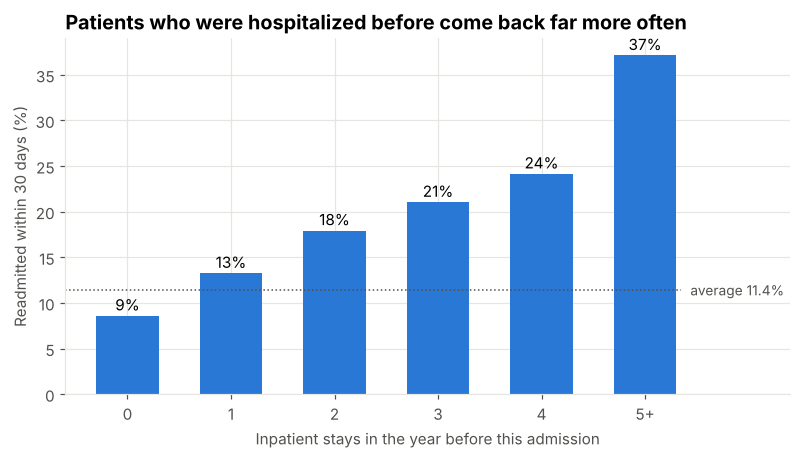

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
bars = ax.bar(prior_rates.index, prior_rates.rate * 100, color=BLUE, width=0.6)
for b, v in zip(bars, prior_rates.rate):
    ax.text(b.get_x() + b.get_width() / 2, v * 100 + 0.6, f"{v:.0%}", ha="center")
ax.hlines(overall * 100, -0.6, 5.35, color=INK2, linestyle=":", linewidth=1)
ax.text(5.4, overall * 100, f" average {overall:.1%}", color=INK2, ha="left", va="center", fontsize=9)
ax.set_xlim(-0.6, 6.4)
ax.set_xlabel("Inpatient stays in the year before this admission")
ax.set_ylabel("Readmitted within 30 days (%)")
ax.set_title("Patients who were hospitalized before come back far more often")
save(fig, "01_prior_stays.png"); plt.show()

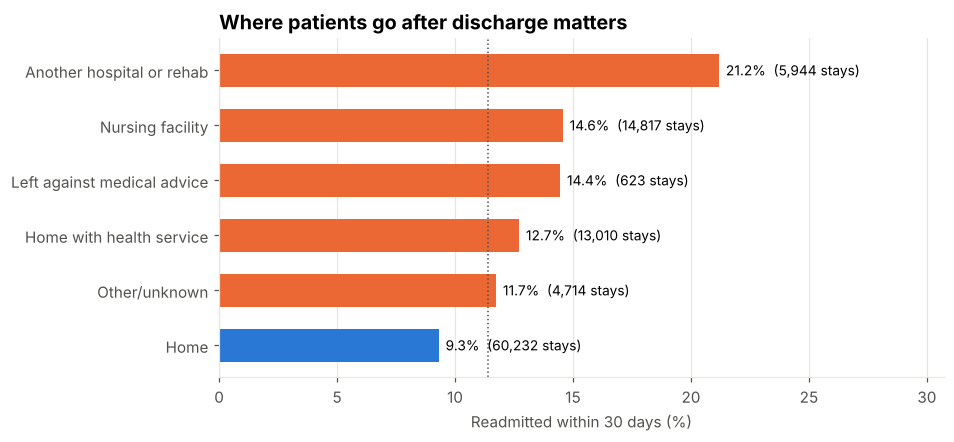

In [8]:
dis = rate_by("discharge_to")
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.barh(dis.index, dis.rate * 100, color=[ORANGE if r > overall else BLUE for r in dis.rate], height=0.6)
for i, (r, n) in enumerate(zip(dis.rate, dis.stays)):
    ax.text(r * 100 + 0.3, i, f"{r:.1%}  ({n:,} stays)", va="center", fontsize=9)
ax.axvline(overall * 100, color=INK2, linestyle=":", linewidth=1)
ax.set_xlabel("Readmitted within 30 days (%)")
ax.set_xlim(0, dis.rate.max() * 100 * 1.45)
ax.grid(axis="y", visible=False)
ax.set_title("Where patients go after discharge matters")
save(fig, "02_discharge_destination.png"); plt.show()

In [9]:
summary_rows = []
for col, label in [("age_group", "Age group"), ("hba1c", "HbA1c test"), ("primary_diagnosis", "Primary diagnosis"),
                   ("admission_type", "Admission type"), ("diabetesMed", "On diabetes medication")]:
    t = d.groupby(col).readmit_30.agg(["mean", "size"])
    for k, r in t.iterrows():
        summary_rows.append({"factor": label, "group": k, "readmit_rate": r["mean"], "stays": int(r["size"])})
pd.DataFrame(summary_rows).set_index(["factor", "group"])

readmit_rate  stays
factor                 group                               
Age group              40-59                   0.101  26667
                       60-79                   0.117  47387
                       80+                     0.125  19023
                       Under 40                0.112   6263
HbA1c test             >7                      0.101   3775
                       >8                      0.099   8137
                       Norm                    0.098   4922
                       Not tested              0.117  82506
Primary diagnosis      Circulatory             0.117  29680
                       Diabetes                0.131   8661
                       Digestive               0.108   9333
                       Genitourinary           0.110   5002
                       Injury                  0.124   6851
                       Missing                 0.250     20
                       Musculoskeletal         0.095   4935
                       Neoplasms               0.109   3131
                       Other                   0.117  17793
                       Respiratory             0.101  13934
Admission type         Elective                0.105  18667
                       Emergency               0.118  52387
                       Unknown                 0.109  10154
                       Urgent                  0.114  18132
On diabetes medication No                      0.099  22623
                       Yes                     0.118  76717

**Takeaways**
- **Prior hospital use is the clearest signal.** Readmission climbs from 8.6% for patients with no inpatient stays in the prior year to 37% for those with five or more.
- **Discharge destination matters.** Patients sent to another hospital, a rehab unit or a nursing facility are readmitted far more often than patients sent home. These patients are sicker, and their care hands off between providers.
- Diabetes as the primary diagnosis carries slightly higher risk than circulatory or respiratory conditions.
- Patients whose HbA1c was tested were readmitted *less* often (about 10% vs 11.7%), consistent with Strack et al.'s finding that measuring HbA1c is associated with better follow-up care.

## 5. Build the models

**Split by patient, not by stay.** Many patients appear more than once. If the same patient's stays landed in both the training and test sets, the model could partly "remember" the patient and look better than it would on new patients. So 25% of *patients* are held out for testing.

Two models are compared:
- **Logistic regression:** simple, transparent, easy to explain to clinicians.
- **Gradient boosting (HistGradientBoosting):** captures interactions and non-linear effects; usually more accurate on tabular data.

A **simple rule** a hospital might already use, "flag anyone with a prior inpatient stay," is included as a benchmark.

In [10]:
X, y, groups = d[NUMERIC + CATEGORICAL], d.readmit_30.values, d.patient_nbr.values
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y[train_idx], y[test_idx]
test = d.iloc[test_idx].copy()

assert not set(groups[train_idx]) & set(groups[test_idx]), "a patient appears in both sets"
print(f"Train: {len(train_idx):,} stays ({y_train.mean():.1%} readmitted)")
print(f"Test:  {len(test_idx):,} stays ({y_test.mean():.1%} readmitted), no patient overlap")

Train: 74,583 stays (11.4% readmitted)
Test:  24,757 stays (11.3% readmitted), no patient overlap


In [11]:
# Logistic regression: scale numbers, one-hot encode categories
logit = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), NUMERIC),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL)])),
    ("model", LogisticRegression(max_iter=3000)),
])
logit.fit(X_train, y_train)
p_logit = logit.predict_proba(X_test)[:, 1]

# Gradient boosting: handles categories natively; early stopping picks the number of trees
def as_category(df):
    df = df.copy()
    for c in CATEGORICAL:
        df[c] = pd.Categorical(df[c], categories=sorted(X[c].unique()))
    return df

gbm = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=500, max_leaf_nodes=31,
                                     min_samples_leaf=50, l2_regularization=1.0,
                                     categorical_features="from_dtype", early_stopping=True,
                                     validation_fraction=0.15, random_state=SEED)
gbm.fit(as_category(X_train), y_train)
p_gbm = gbm.predict_proba(as_category(X_test))[:, 1]
print(f"Gradient boosting stopped at {gbm.n_iter_} trees")

# benchmark rule
rule = (X_test.number_inpatient > 0).astype(int).values

Gradient boosting stopped at 91 trees


## 6. How good are the models?

- **AUC (ROC):** the chance the model ranks a random readmitted patient above a random non-readmitted one. 0.5 is a coin flip, 1.0 is perfect.
- **Average precision:** area under the precision-recall curve. The baseline is the readmission rate (about 0.11).
- **Top 10% / top 20%:** if the care team can only reach that share of patients, what share of the people they reach are readmitted (precision), and what share of all readmissions do they catch (recall)?

In [12]:
def top_k(p, frac):
    k = int(round(len(p) * frac))
    chosen = np.argsort(-p, kind="stable")[:k]
    return y_test[chosen].mean(), y_test[chosen].sum() / y_test.sum()

rows = {}
for name, p in [("Logistic regression", p_logit), ("Gradient boosting", p_gbm)]:
    prec10, rec10 = top_k(p, 0.10)
    prec20, rec20 = top_k(p, 0.20)
    rows[name] = {"AUC": roc_auc_score(y_test, p), "avg precision": average_precision_score(y_test, p),
                  "Brier score": brier_score_loss(y_test, p),
                  "top 10% precision": prec10, "top 10% recall": rec10, "top 10% lift": prec10 / y_test.mean(),
                  "top 20% precision": prec20, "top 20% recall": rec20}
flag_rate = rule.mean()
rows["Rule: any prior inpatient stay"] = {
    "AUC": roc_auc_score(y_test, rule), "avg precision": np.nan, "Brier score": np.nan,
    "top 10% precision": np.nan, "top 10% recall": np.nan, "top 10% lift": np.nan,
    "top 20% precision": np.nan, "top 20% recall": np.nan}
results = pd.DataFrame(rows).T
print(f"The rule flags {flag_rate:.0%} of patients; precision {y_test[rule == 1].mean():.1%}, "
      f"recall {y_test[rule == 1].sum() / y_test.sum():.1%}")
results

The rule flags 33% of patients; precision 16.8%, recall 49.0%


,AUC,avg precision,Brier score,top 10% precision,top 10% recall,top 10% lift,top 20% precision,top 20% recall
Logistic regression,0.661,0.209,0.096,0.244,0.217,2.169,0.208,0.369
Gradient boosting,0.667,0.215,0.096,0.261,0.232,2.316,0.214,0.380
Rule: any prior inpatient stay,0.591,NaN,NaN,NaN,NaN,NaN,NaN,NaN


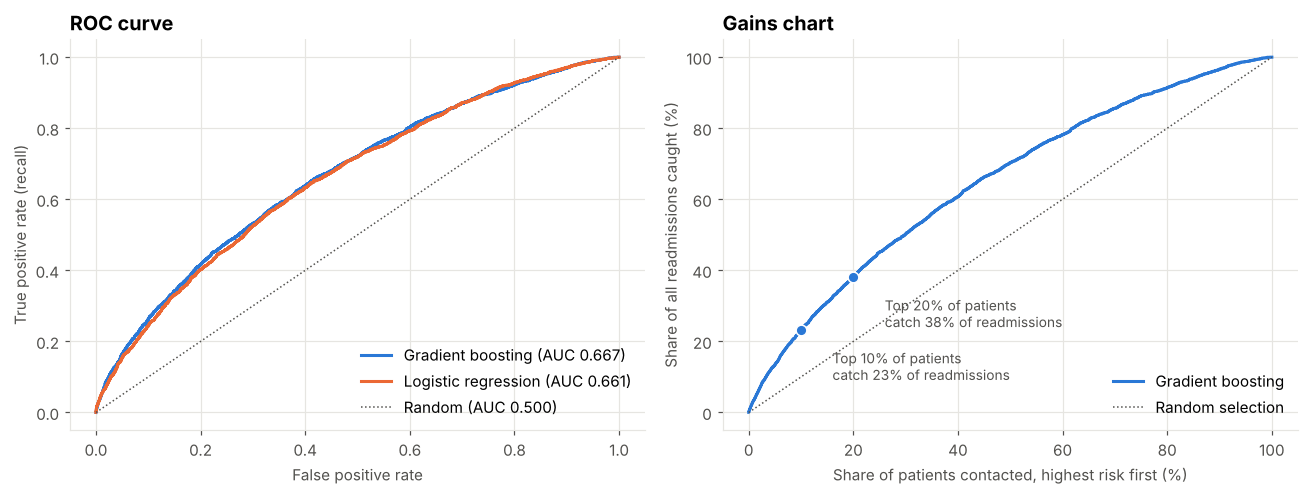

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
for name, p, col in [("Gradient boosting", p_gbm, BLUE), ("Logistic regression", p_logit, ORANGE)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=col, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], color=INK2, linestyle=":", linewidth=1, label="Random (AUC 0.500)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)")
ax.legend(frameon=False, loc="lower right"); ax.set_title("ROC curve")

ax = axes[1]
order = np.argsort(-p_gbm, kind="stable")
share = np.arange(1, len(order) + 1) / len(order)
captured = np.cumsum(y_test[order]) / y_test.sum()
ax.plot(share * 100, captured * 100, color=BLUE, label="Gradient boosting")
ax.plot([0, 100], [0, 100], color=INK2, linestyle=":", linewidth=1, label="Random selection")
for frac in [0.1, 0.2]:
    _, rec = top_k(p_gbm, frac)
    ax.plot(frac * 100, rec * 100, "o", color=BLUE, markersize=7, markeredgecolor="white")
    ax.annotate(f"Top {frac:.0%} of patients\ncatch {rec:.0%} of readmissions", (frac * 100, rec * 100),
                xytext=(frac * 100 + 6, rec * 100 - 14), fontsize=9, color=INK2)
ax.set_xlabel("Share of patients contacted, highest risk first (%)")
ax.set_ylabel("Share of all readmissions caught (%)")
ax.legend(frameon=False, loc="lower right"); ax.set_title("Gains chart")
fig.tight_layout()
save(fig, "03_model_performance.png"); plt.show()

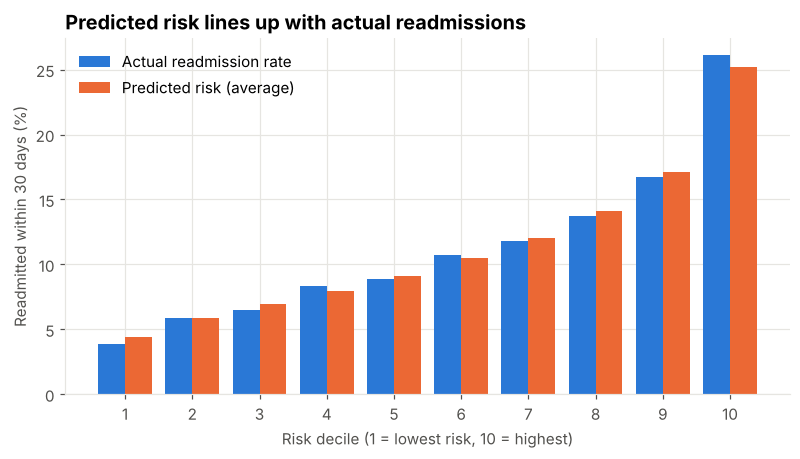

,predicted,actual,stays
risk_decile,,,
1,0.044,0.038,2476
2,0.059,0.059,2476
3,0.069,0.065,2475
4,0.079,0.084,2476
5,0.091,0.089,2476
6,0.105,0.107,2475
7,0.121,0.118,2476
8,0.141,0.137,2475
9,0.171,0.168,2476


In [14]:
# Calibration: do predicted risks match what actually happened?
test["risk_gbm"] = p_gbm
test["risk_decile"] = pd.qcut(test.risk_gbm.rank(method="first"), 10, labels=range(1, 11))
calib = test.groupby("risk_decile", observed=True).agg(predicted=("risk_gbm", "mean"),
                                                       actual=("readmit_30", "mean"), stays=("readmit_30", "size"))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(1, 11)
ax.bar(x - 0.2, calib.actual * 100, width=0.4, color=BLUE, label="Actual readmission rate")
ax.bar(x + 0.2, calib.predicted * 100, width=0.4, color=ORANGE, label="Predicted risk (average)")
ax.set_xticks(x); ax.set_xlabel("Risk decile (1 = lowest risk, 10 = highest)")
ax.set_ylabel("Readmitted within 30 days (%)")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Predicted risk lines up with actual readmissions")
save(fig, "04_calibration_by_decile.png"); plt.show()
calib

**Takeaways**
- Gradient boosting is slightly better than logistic regression (AUC 0.67 vs 0.66). Both are in line with published results on this dataset, which typically fall between 0.64 and 0.70. Readmission is hard to predict from hospital records alone, because much of the risk comes from what happens after discharge.
- The ranking is still useful. The top-risk decile is readmitted at about **26%**, more than double the 11% average, and the lowest decile at under 5%.
- Predicted risks match actual rates closely in every decile, so the scores can be read as real probabilities.
- The simple "any prior stay" rule flags 33% of patients and catches 49% of readmissions, with 16.8% precision. Flagging the same 30% with the model catches 50% with 18.9% precision, and unlike the rule, the model can rank patients so a small team starts with the riskiest.

## 7. What does the model rely on?

**Permutation importance** shuffles one feature at a time on the test set and measures how much AUC drops. A large drop means the model depends on that feature. **Odds ratios** from the logistic regression show the direction of each effect.

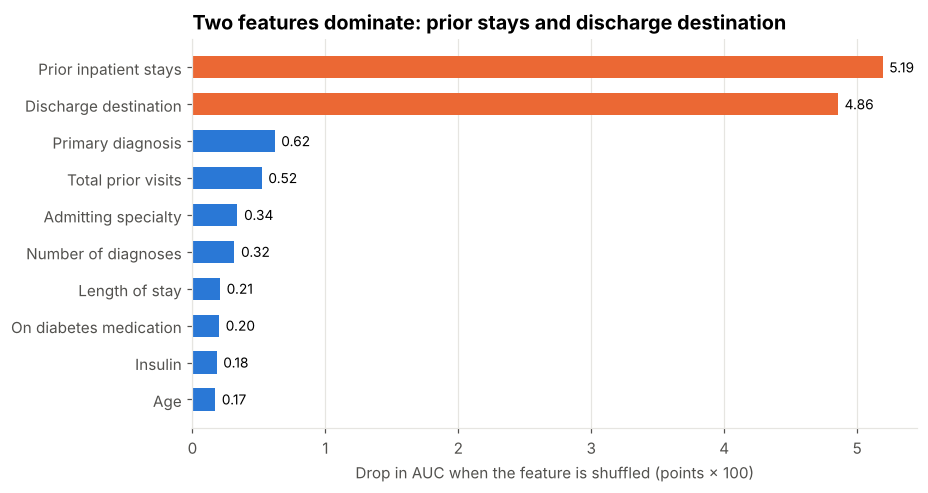

In [15]:
perm = permutation_importance(gbm, as_category(X_test), y_test, scoring="roc_auc",
                              n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
top = imp.head(10)[::-1]

nice = {"number_inpatient": "Prior inpatient stays", "discharge_to": "Discharge destination",
        "total_prior_visits": "Total prior visits", "number_emergency": "Prior ER visits",
        "number_diagnoses": "Number of diagnoses", "time_in_hospital": "Length of stay",
        "num_medications": "Number of medications", "num_lab_procedures": "Number of lab tests",
        "age": "Age", "specialty": "Admitting specialty", "primary_diagnosis": "Primary diagnosis",
        "admission_source": "Admission source", "number_outpatient": "Prior outpatient visits",
        "num_procedures": "Number of procedures", "diabetesMed": "On diabetes medication",
        "admission_type": "Admission type", "n_diabetes_meds": "Number of diabetes drugs",
        "insulin": "Insulin", "metformin": "Metformin", "hba1c": "HbA1c result", "glucose": "Glucose result",
        "gender": "Sex", "change": "Medication changed", "n_dose_changes": "Dose changes"}

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.barh([nice.get(k, k) for k in top.index], top.values * 100,
        color=[ORANGE if k in ("number_inpatient", "discharge_to") else BLUE for k in top.index], height=0.6)
for i, v in enumerate(top.values):
    ax.text(v * 100 + 0.05, i, f"{v * 100:.2f}", va="center", fontsize=9)
ax.set_xlabel("Drop in AUC when the feature is shuffled (points × 100)")
ax.grid(axis="y", visible=False)
ax.set_title("Two features dominate: prior stays and discharge destination")
save(fig, "05_feature_importance.png"); plt.show()

In [16]:
names = logit.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(logit.named_steps["model"].coef_[0], index=names)
odds = np.exp(coefs).rename("odds ratio").to_frame()
odds["feature"] = odds.index.str.replace("num__", "").str.replace("cat__", "")
print("Numeric odds ratios are per one standard deviation increase.")
odds.sort_values("odds ratio", ascending=False).head(8)[["feature", "odds ratio"]].reset_index(drop=True)

Numeric odds ratios are per one standard deviation increase.


,feature,odds ratio
0,discharge_to_Another hospital or rehab,1.615
1,specialty_Nephrology,1.325
2,number_inpatient,1.312
3,metformin_Down,1.121
4,total_prior_visits,1.112
5,age_[70-80),1.103
6,number_diagnoses,1.086
7,age_[20-30),1.083


**Takeaways:** Two features carry the model: **prior inpatient stays** and **discharge destination**. Each is worth about 5 AUC points; every other feature adds less than 1 point. The logistic regression agrees: the largest odds ratio belongs to discharge to another hospital or rehab (about 1.6), and each standard deviation of prior inpatient stays (about 1.3 more stays) raises the odds of readmission by about 31%. A nephrology (kidney) admitting specialty also stands out. Clinically this makes sense: frequent, complex patients whose care is handed off between facilities are the ones who come back.

## 8. Business case: is a targeted follow-up program worth it?

Suppose the hospital enrolls high-risk patients in a post-discharge program (care-transition coaching, a follow-up call and a pharmacist medication review). Assumptions, with sources:

| Assumption | Value | Source |
|---|---|---|
| Cost of one readmission | **$16,300** | AHRQ HCUP Statistical Brief #304 (2020 average) |
| Program cost per patient | **$300** | Care Transitions Intervention, about $298 per patient (Gardner et al., 2014) |
| Share of readmissions the program prevents | **20%** | Conservative; the CTI trial found odds ratio 0.61 (about 34% fewer) |

Results are scaled to **1,000 discharges** and use the test set, which the model never saw.

In [17]:
READMIT_COST, PROGRAM_COST, EFFECT = 16_300, 300, 0.20

def program_value(p, frac, cost=PROGRAM_COST, effect=EFFECT, readmit_cost=READMIT_COST):
    """Savings per 1,000 discharges if the top `frac` of patients by risk `p` are enrolled."""
    k = int(round(len(p) * frac))
    chosen = np.argsort(-p, kind="stable")[:k]
    readmits_in_group = y_test[chosen].sum()
    prevented = effect * readmits_in_group
    savings, spend = prevented * readmit_cost, k * cost
    scale = 1000 / len(p)
    return {"enrolled": k * scale, "readmissions in group": readmits_in_group * scale,
            "readmissions prevented": prevented * scale, "program cost": spend * scale,
            "savings": savings * scale, "net savings": (savings - spend) * scale,
            "return per $1": savings / spend if spend else np.nan}

rng = np.random.default_rng(SEED)
random_scores = rng.random(len(y_test))
rows = {}
for frac in [0.05, 0.10, 0.20, 0.30, 0.50, 1.00]:
    rows[f"Model: top {frac:.0%}"] = program_value(p_gbm, frac)
rows["Random 10% (no model)"] = program_value(random_scores, 0.10)
biz = pd.DataFrame(rows).T
biz.style.format({"enrolled": "{:,.0f}", "readmissions in group": "{:,.1f}", "readmissions prevented": "{:,.1f}",
                  "program cost": "${:,.0f}", "savings": "${:,.0f}", "net savings": "${:,.0f}",
                  "return per $1": "${:,.2f}"})

,enrolled,readmissions in group,readmissions prevented,program cost,savings,net savings,return per $1
Model: top 5%,50,15.1,3.0,"$15,002","$49,117","$34,115",$3.27
Model: top 10%,100,26.1,5.2,"$30,004","$85,065","$55,062",$2.84
Model: top 20%,200,42.9,8.6,"$59,995","$139,712","$79,717",$2.33
Model: top 30%,300,56.6,11.3,"$89,999","$184,484","$94,485",$2.05
Model: top 50%,500,79.2,15.8,"$149,994","$258,093","$108,099",$1.72
Model: top 100%,"1,000",112.7,22.5,"$300,000","$367,255","$67,255",$1.22
Random 10% (no model),100,11.9,2.4,"$30,004","$38,846","$8,842",$1.29


Break-even risk: enroll a patient only if predicted risk > 9.2%
Share of test patients above break-even: 54%


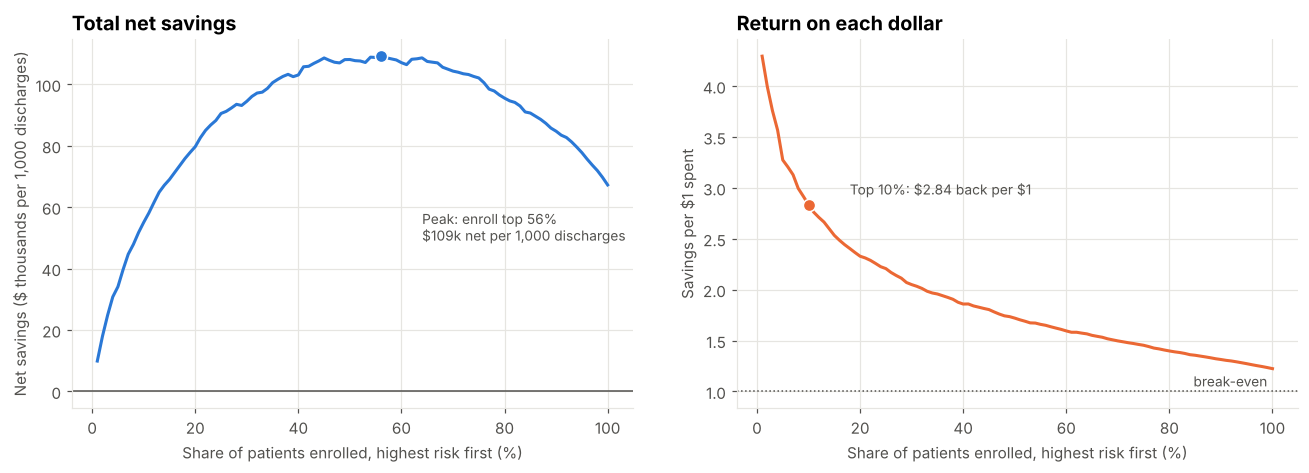

In [18]:
fracs = np.linspace(0.01, 1, 100)
curve = pd.DataFrame([program_value(p_gbm, f) for f in fracs], index=fracs * 100)
best = curve["net savings"].idxmax()
breakeven_risk = PROGRAM_COST / (EFFECT * READMIT_COST)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
ax.plot(curve.index, curve["net savings"] / 1000, color=BLUE)
ax.axhline(0, color=INK2, linewidth=1)
ax.plot(best, curve.loc[best, "net savings"] / 1000, "o", color=BLUE, markeredgecolor="white", markersize=8)
ax.annotate(f"Peak: enroll top {best:.0f}%\n${curve.loc[best, 'net savings']/1000:,.0f}k net per 1,000 discharges",
            (best, curve.loc[best, "net savings"] / 1000), xytext=(best + 8, curve.loc[best, "net savings"] / 1000 * 0.45),
            fontsize=9, color=INK2)
ax.set_xlabel("Share of patients enrolled, highest risk first (%)")
ax.set_ylabel("Net savings ($ thousands per 1,000 discharges)")
ax.set_title("Total net savings")

ax = axes[1]
ax.plot(curve.index, curve["return per $1"], color=ORANGE)
ax.axhline(1, color=INK2, linewidth=1, linestyle=":")
ax.text(99, 1.05, "break-even", color=INK2, fontsize=9, ha="right")
r10 = program_value(p_gbm, 0.10)["return per $1"]
ax.plot(10, r10, "o", color=ORANGE, markeredgecolor="white", markersize=8)
ax.annotate(f"Top 10%: ${r10:.2f} back per $1", (10, r10), xytext=(18, r10 + 0.1), fontsize=9, color=INK2)
ax.set_xlabel("Share of patients enrolled, highest risk first (%)")
ax.set_ylabel("Savings per $1 spent")
ax.set_title("Return on each dollar")
fig.tight_layout()
save(fig, "06_business_case.png"); plt.show()
print(f"Break-even risk: enroll a patient only if predicted risk > {breakeven_risk:.1%}")
print(f"Share of test patients above break-even: {(p_gbm > breakeven_risk).mean():.0%}")

The two charts answer different questions. **Return per dollar is highest at the top of the list:** the riskiest patients give the most back. **Total net savings** keep growing as long as each added patient's risk is above the break-even point (cost ÷ (effectiveness × readmission cost) ≈ 9.2%). In practice, care-team capacity is the real limit, so the model's job is to put the right patients at the front of the line.

### How sensitive is this to the assumptions?

In [19]:
effects = [0.10, 0.15, 0.20, 0.25, 0.30]
costs = [150, 300, 500, 750]
grid = pd.DataFrame({f"${c}": [program_value(p_gbm, 0.10, cost=c, effect=e)["return per $1"] for e in effects]
                     for c in costs}, index=[f"{e:.0%} prevented" for e in effects])
grid.index.name = "Top 10% enrolled; program cost →"
grid.style.format("${:.2f}").background_gradient(cmap="RdYlGn", vmin=0, vmax=3, axis=None)

,$150,$300,$500,$750
Top 10% enrolled; program cost →,,,,
10% prevented,$2.84,$1.42,$0.85,$0.57
15% prevented,$4.25,$2.13,$1.28,$0.85
20% prevented,$5.67,$2.84,$1.70,$1.13
25% prevented,$7.09,$3.54,$2.13,$1.42
30% prevented,$8.51,$4.25,$2.55,$1.70


**Takeaways**
- Targeting the **top 10%** with a $300 program that prevents 20% of readmissions returns about **$2.84 per $1**, saving roughly **$55,000 net per 1,000 discharges**. Picking the same number of patients at random returns about $1.29 per $1, so the model more than doubles the return.
- Targeting the top 10% stays profitable in **17 of 20** assumption scenarios. It loses money only when the program prevents 10% of readmissions and costs $500 or more, or costs $750 and prevents 15% or fewer.
- Recommendation: start with the **top 10 to 20%** of patients, where each dollar works hardest, and expand as capacity allows down to the break-even risk of about 9%.

## 9. Fairness check

A model used to allocate care should work equally well for everyone. Race was excluded from the model, but other features can act as proxies, so the model is audited by **race, sex and age**.

For each group, using the "top 20%" cutoff:
- **AUC:** how well the model ranks patients within the group.
- **Flag rate:** share of the group selected for the program.
- **Recall (true positive rate):** share of the group's actual readmissions that get flagged. Large gaps mean one group's at-risk patients are being missed (the *equal opportunity* criterion).
- **Predicted vs actual rate:** whether the model over- or under-estimates risk for the group.

In [20]:
cutoff = np.quantile(p_gbm, 0.80)
test["flagged"] = (p_gbm >= cutoff).astype(int)

def audit(col, order):
    rows = []
    for g in order:
        s = test[test[col] == g]
        pos = s.readmit_30 == 1
        rows.append({"group": g, "stays": len(s), "actual rate": s.readmit_30.mean(),
                     "predicted rate": s.risk_gbm.mean(),
                     "AUC": roc_auc_score(s.readmit_30, s.risk_gbm),
                     "flag rate": s.flagged.mean(),
                     "recall": s.flagged[pos].mean(),
                     "precision": s.readmit_30[s.flagged == 1].mean()})
    return pd.DataFrame(rows).set_index("group")

fair = {
    "Race": audit("race_group", ["White", "African American", "Hispanic", "Asian/Other", "Unknown"]),
    "Sex": audit("gender", ["Female", "Male"]),
    "Age": audit("age_group", ["Under 40", "40-59", "60-79", "80+"]),
}
fair_table = pd.concat(fair, names=["attribute", "group"])
fair_table

stays  actual rate  ...  recall  precision
attribute group                                 ...                   
Race      White             18563        0.115  ...   0.386      0.221
          African American   4607        0.108  ...   0.371      0.191
          Hispanic            507        0.097  ...   0.408      0.230
          Asian/Other         519        0.106  ...   0.345      0.260
          Unknown             561        0.080  ...   0.244      0.125
Sex       Female            13395        0.113  ...   0.398      0.216
          Male              11362        0.113  ...   0.360      0.213
Age       Under 40           1557        0.113  ...   0.580      0.328
          40-59              6688        0.103  ...   0.351      0.241
          60-79             11689        0.113  ...   0.387      0.201
          80+                4823        0.124  ...   0.341      0.188

[11 rows x 7 columns]

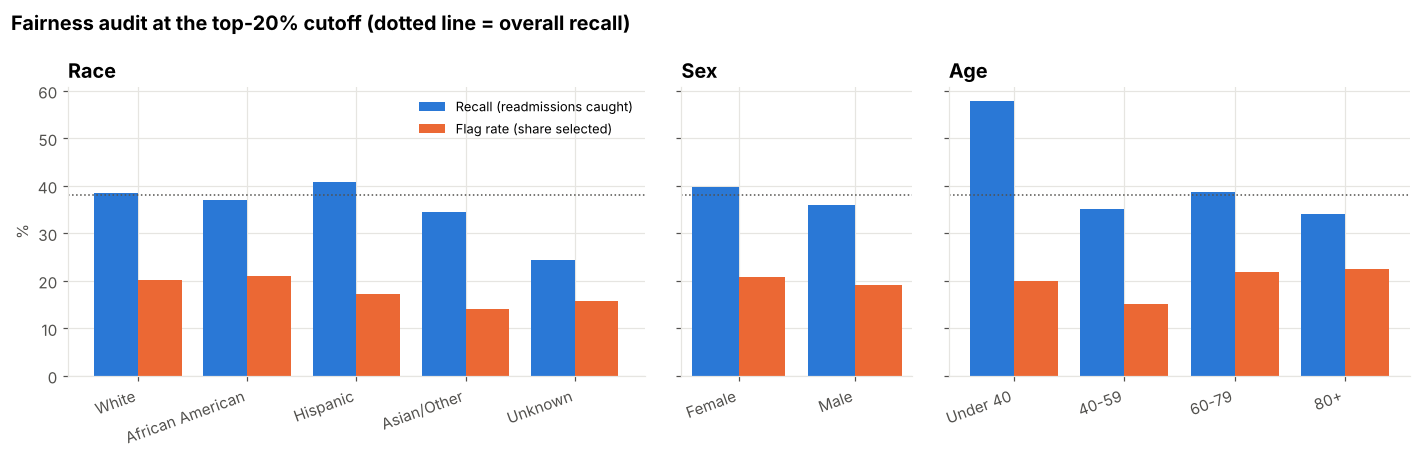

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True, gridspec_kw={"width_ratios": [5, 2, 4]})
for ax, (attr, t) in zip(axes, fair.items()):
    x = np.arange(len(t))
    ax.bar(x - 0.2, t["recall"] * 100, width=0.4, color=BLUE, label="Recall (readmissions caught)")
    ax.bar(x + 0.2, t["flag rate"] * 100, width=0.4, color=ORANGE, label="Flag rate (share selected)")
    ax.set_xticks(x); ax.set_xticklabels(t.index, rotation=20, ha="right")
    ax.set_title(attr)
    ax.axhline(test.flagged[test.readmit_30 == 1].mean() * 100, color=INK2, linestyle=":", linewidth=1)
axes[0].set_ylabel("%")
axes[0].legend(frameon=False, loc="upper right", fontsize=8.5)
fig.suptitle("Fairness audit at the top-20% cutoff (dotted line = overall recall)", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "07_fairness_audit.png"); plt.show()

**Takeaways**
- **Race:** recall is similar for White (39%), African American (37%) and Hispanic (41%) patients, and predicted risk tracks actual risk in each group. Precision is a little lower for African American patients (19% vs 22%). The Asian/Other and Unknown groups are small (about 500 stays and 50 readmissions each), so their numbers are too uncertain to over-read.
- **Sex:** the model catches 40% of women's readmissions and 36% of men's. The gap is small but worth tracking.
- **Age:** this is where the model differs most. It ranks patients under 40 best (AUC 0.77, recall 58%) and patients **80+** worst (AUC 0.61, recall 34%), even though older patients are flagged most often. Patients 40 to 59 are flagged least often (15%). Readmission in the very old seems to depend on things hospital records don't capture, such as frailty and support at home.
- **Recommendation:** before deployment, monitor recall by age and race every quarter. For patients 80+, add information the model lacks (frailty screening, caregiver support) rather than relying on the score alone.

## 10. Conclusions

| Audience | Recommendation |
|---|---|
| Care management | Prioritize patients with prior inpatient stays and those discharged to another facility; the model ranks them automatically at discharge. |
| Hospital finance | A targeted program for the top 10 to 20% of patients is expected to return about $2 to $3 per $1 under conservative assumptions. |
| Quality & compliance | Audit the model's recall by age and race quarterly; keep race out of the model's inputs. |
| Data teams | Add post-discharge data (follow-up visits, pharmacy fills, social factors) to push AUC beyond the 0.67 ceiling of hospital-only records. |

### Limitations
- **Old data (1999 to 2008).** Treatment patterns and coding (ICD-9 rather than ICD-10) have changed; the model would need retraining on current data before use.
- **Moderate accuracy.** AUC of 0.67 means many readmissions are still missed; the model supports, not replaces, clinical judgment.
- **Business case relies on assumptions.** Program cost and effectiveness come from published studies, not this population; the sensitivity table shows how results change.
- **No information after discharge,** which is where much readmission risk arises.
- **Observational data.** Associations (such as HbA1c testing and lower readmission) are not proof of cause.

### References
- Strack, B. et al. (2014). *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records.* BioMed Research International.
- AHRQ Healthcare Cost and Utilization Project. *Statistical Brief #304: Characteristics of 30-Day All-Cause Hospital Readmissions, 2016–2020.*
- Gardner, R. et al. (2014). *Is Implementation of the Care Transitions Intervention Associated with Cost Avoidance After Hospital Discharge?* Journal of General Internal Medicine, 29(6), 878–884.
- UCI Machine Learning Repository: *Diabetes 130-US Hospitals for Years 1999–2008.*